# Imports and Installations

In [1]:
! pip install -U kneed contextily osmnx optuna optuna-integration[xgboost] -q

In [2]:
import numpy as np
import pandas as pd

from math import radians, cos, sin, asin, sqrt

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_squared_log_error, root_mean_squared_error
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA

import xgboost as xgb
from xgboost import XGBRegressor

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
import seaborn as sns
import contextily as cx

from kneed import KneeLocator

import osmnx as ox
import networkx as nx

import optuna
import json

import gc
import warnings

warnings.filterwarnings('ignore')

# Data Loads

In [3]:
train_df = pd.read_csv('/kaggle/input/competitions/nyc-taxi-trip-duration/train.zip')
test_df = pd.read_csv('/kaggle/input/competitions/nyc-taxi-trip-duration/test.zip')
train_osrm = pd.read_csv('/kaggle/input/datasets/atmarouane/nyc-taxi-trip-noisy/train_augmented.csv')
test_osrm  = pd.read_csv('/kaggle/input/datasets/atmarouane/nyc-taxi-trip-noisy/test_augmented.csv')
weather = pd.read_csv('/kaggle/input/datasets/gilyazovrasim/weather/weatherdata.csv')

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")

Train shape: (1458644, 11)
Test shape: (625134, 9)


# Exploratory Data Analysis (EDA)

In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  object 
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  object 
 3   dropoff_datetime    1458644 non-null  object 
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  object 
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), object(4)
memory usage: 122.4+ MB


In [5]:
train_df.describe()

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06
mean,1.534950e+00,1.664530e+00,-7.397349e+01,4.075092e+01,-7.397342e+01,4.075180e+01,9.594923e+02
std,4.987772e-01,1.314242e+00,7.090186e-02,3.288119e-02,7.064327e-02,3.589056e-02,5.237432e+03
min,1.000000e+00,0.000000e+00,-1.219333e+02,3.435970e+01,-1.219333e+02,3.218114e+01,1.000000e+00
25%,1.000000e+00,1.000000e+00,-7.399187e+01,4.073735e+01,-7.399133e+01,4.073588e+01,3.970000e+02
50%,2.000000e+00,1.000000e+00,-7.398174e+01,4.075410e+01,-7.397975e+01,4.075452e+01,6.620000e+02
75%,2.000000e+00,2.000000e+00,-7.396733e+01,4.076836e+01,-7.396301e+01,4.076981e+01,1.075000e+03
max,2.000000e+00,9.000000e+00,-6.133553e+01,5.188108e+01,-6.133553e+01,4.392103e+01,3.526282e+06


## Well, min and max are far from mean and 25/75%. Have to check for outliers

### Vendor id

In [6]:
train_df['vendor_id'].value_counts()

vendor_id
2    780302
1    678342
Name: count, dtype: int64

### Feels normal

### Passenger count

In [7]:
train_df['passenger_count'].value_counts()

passenger_count
1    1033540
2     210318
5      78088
3      59896
6      48333
4      28404
0         60
7          3
9          1
8          1
Name: count, dtype: int64

### Count of 0, 7, 8, 9 passangers are just outliers

In [8]:
train_df = train_df[(train_df['passenger_count'] > 0) & (train_df['passenger_count'] < 7)]

### Want to check if there are non-valid coords (too far from New-York); will delete them as outliers

In [9]:
LAT_MIN, LAT_MAX = 40.4, 41.2
LON_MIN, LON_MAX = -74.5, -73.5

In [10]:
def is_valid_coords(df):
    return (
        df['pickup_latitude'].between(LAT_MIN, LAT_MAX) &
        df['pickup_longitude'].between(LON_MIN, LON_MAX) &
        df['dropoff_latitude'].between(LAT_MIN, LAT_MAX) &
        df['dropoff_longitude'].between(LON_MIN, LON_MAX)
    )

mask = is_valid_coords(train_df)
print(f"Deleted: {(~mask).sum()} samples ({(~mask).mean()*100:.2f}%)")
train_df = train_df[mask].reset_index(drop=True)

Deleted: 216 samples (0.01%)


## Let`s take a look at the map

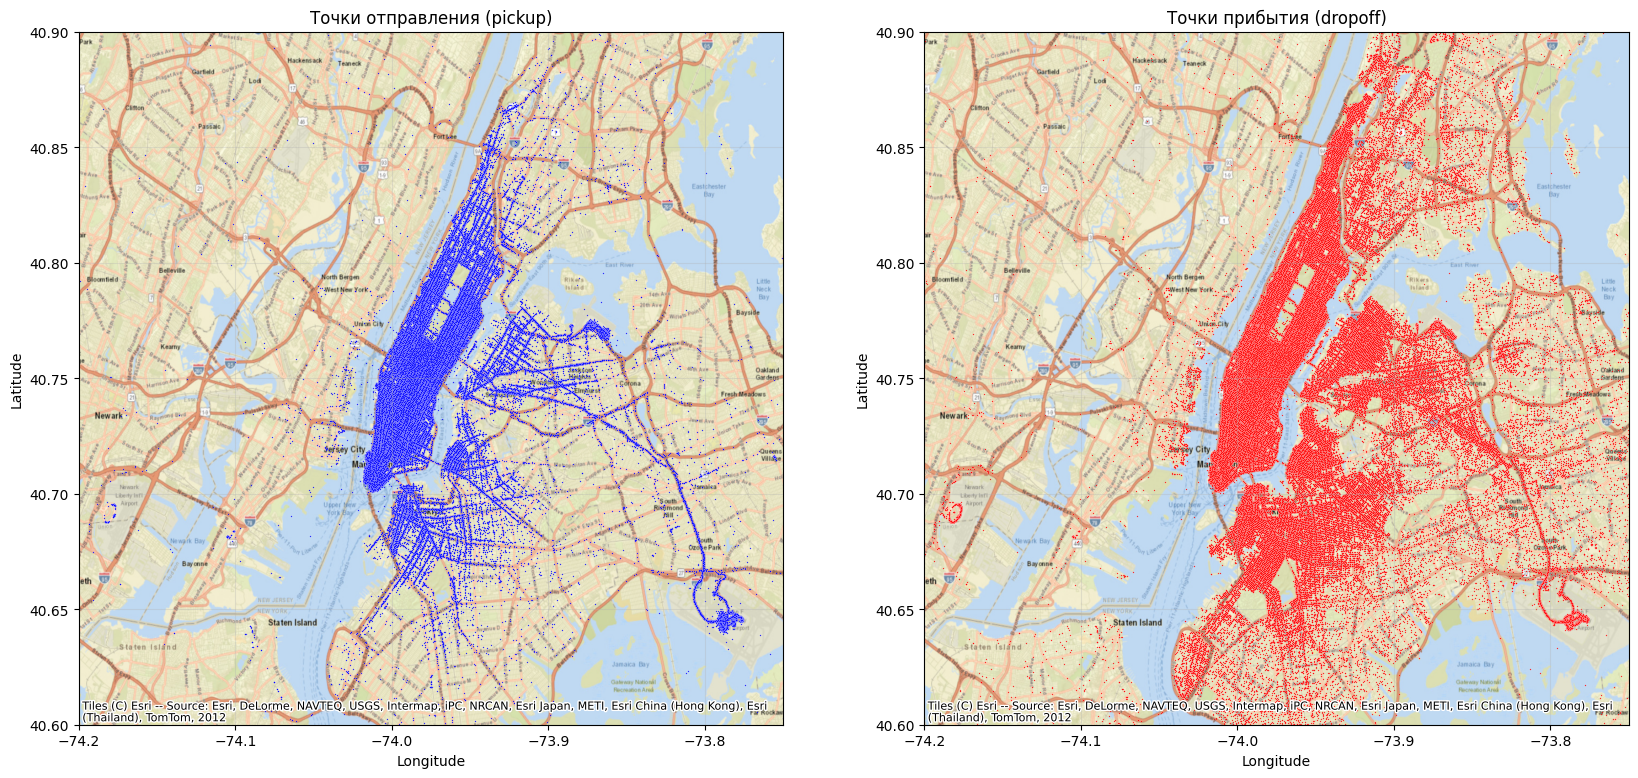

In [11]:
LON_MIN, LON_MAX = -74.20, -73.75
LAT_MIN, LAT_MAX = 40.60, 40.90

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

configs = [
    ('pickup_longitude',  'pickup_latitude',  'blue',  'Точки отправления (pickup)'),
    ('dropoff_longitude', 'dropoff_latitude', 'red', 'Точки прибытия (dropoff)'),
]

for ax, (lon_col, lat_col, base_color, title) in zip(axes, configs):
    sns.scatterplot(
        x=lon_col, y=lat_col, data=train_df,
        s=1, alpha=0.8, ax=ax, color=base_color, legend=False,
    )

    ax.set_xlim(LON_MIN, LON_MAX)
    ax.set_ylim(LAT_MIN, LAT_MAX)
    cx.add_basemap(ax, crs="EPSG:4326", zoom=12, source=cx.providers.Esri.WorldStreetMap)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_title(title)
    ax.grid(alpha=0.3)

## Let`s check for pickup/dropoff maps with top-10 anchors in New-York

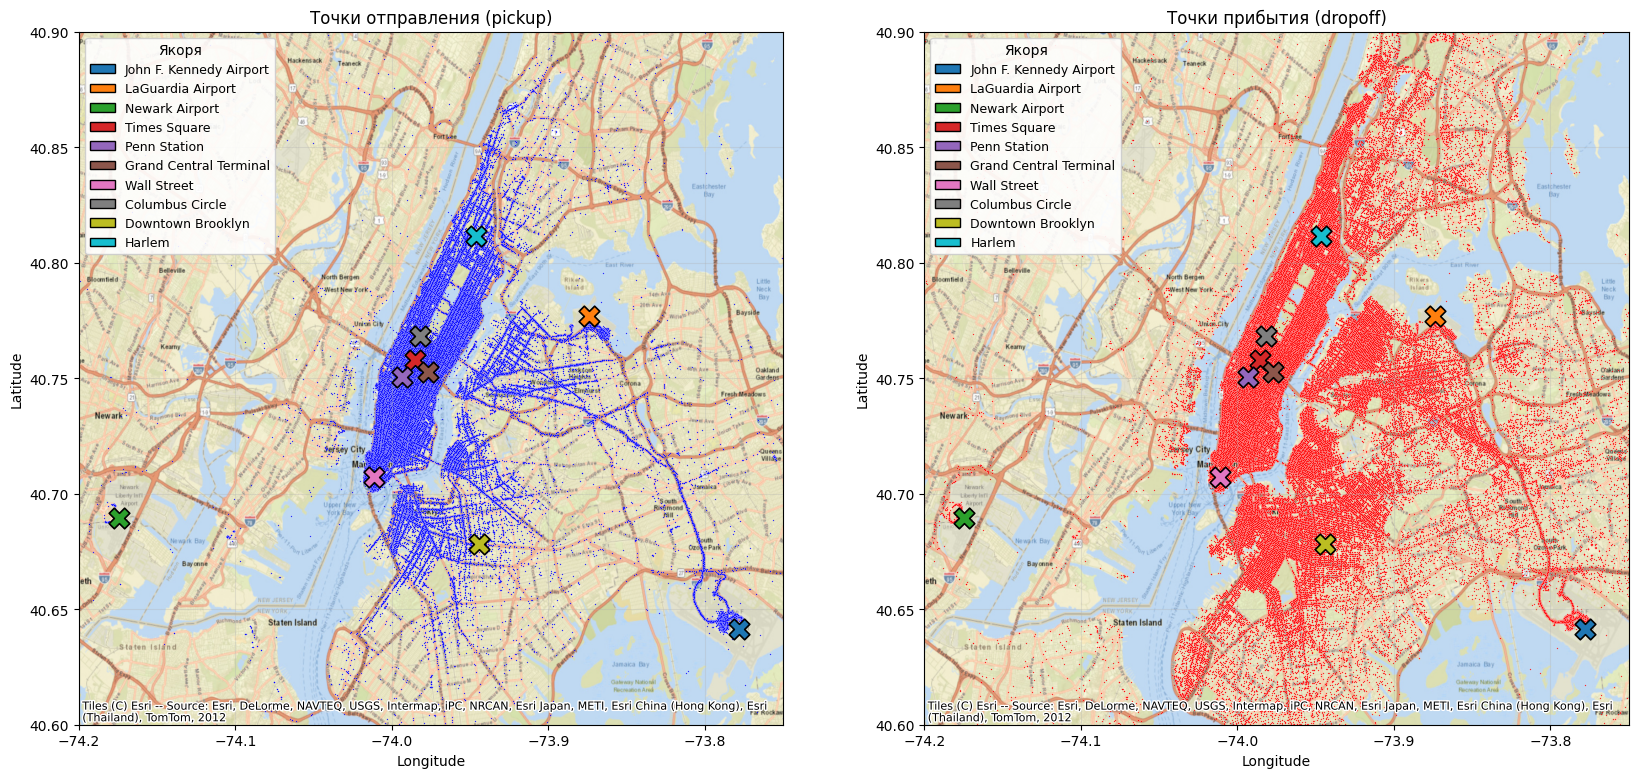

In [12]:
ANCHORS = {
    'John F. Kennedy Airport':    (40.6413, -73.7781),
    'LaGuardia Airport':          (40.7769, -73.8740),
    'Newark Airport':             (40.6895, -74.1745),
    'Times Square':               (40.7580, -73.9855),
    'Penn Station':               (40.7506, -73.9935),
    'Grand Central Terminal':     (40.7527, -73.9772),
    'Wall Street':                (40.7074, -74.0113),
    'Columbus Circle':            (40.7681, -73.9819),
    'Downtown Brooklyn':          (40.6782, -73.9442),
    'Harlem':                     (40.8116, -73.9465),
}

anchor_colors = dict(zip(ANCHORS.keys(), plt.cm.tab10.colors))

anchor_handles = [
    Patch(
        facecolor=anchor_colors[name],
        edgecolor='black',
        label=name,
    )
    for name in ANCHORS
]

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

for ax, (lon_col, lat_col, base_color, title) in zip(axes, configs):
    sns.scatterplot(
        x=lon_col, y=lat_col, data=train_df,
        s=1, alpha=0.8, ax=ax, color=base_color, legend=False,
    )

    for anchor_name, (alat, alon) in ANCHORS.items():
        ax.scatter(
            alon, alat,
            marker='X', s=220,
            c=[anchor_colors[anchor_name]],
            edgecolors='black', linewidths=1.2,
            zorder=6,
        )

    ax.set_xlim(LON_MIN, LON_MAX)
    ax.set_ylim(LAT_MIN, LAT_MAX)
    cx.add_basemap(ax, crs="EPSG:4326", zoom=12, source=cx.providers.Esri.WorldStreetMap)

    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(
        handles=anchor_handles,
        loc='upper left',
        title='Якоря',
        fontsize=9,
        title_fontsize=10,
        framealpha=0.9,
    )

## Trip duration

## Well, I am going to use log(trip_duration) instead of using raw target. Firstly, this way I do not need to get rid of outliers (they will be normalized). Secondly, look at the histograms of raw target and log(target) below: the second one looks way better and near to normal distribution

Text(0.5, 0.98, 'Сравнение распределения целевой переменной')

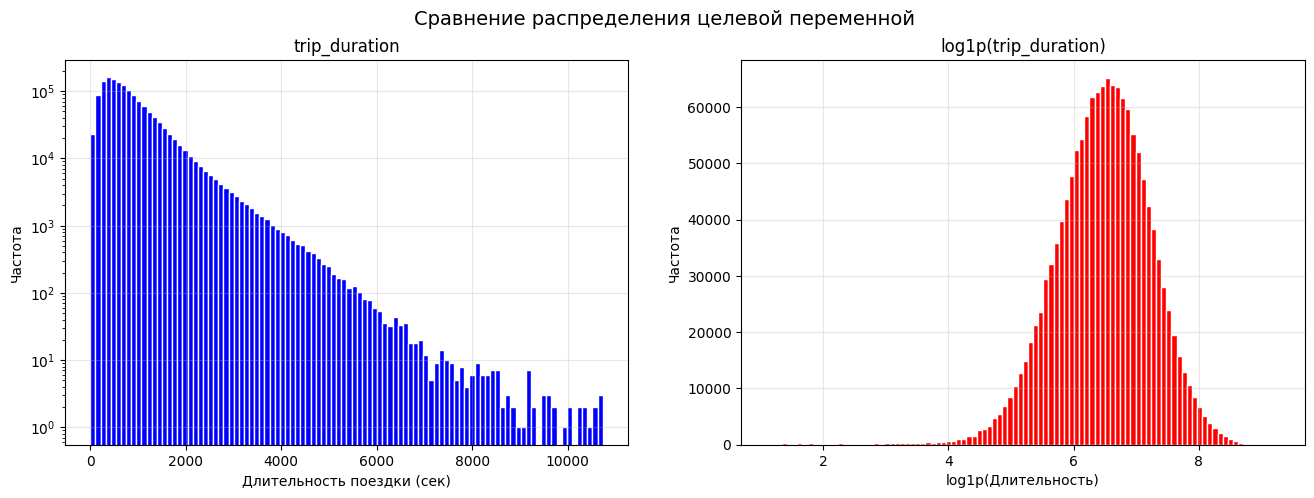

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
dt = train_df[(train_df['trip_duration']>1)&(train_df['trip_duration']<10800)]['trip_duration']
axes[0].hist(dt, bins=100, color='blue', edgecolor='white')
axes[0].set_yscale('log')
axes[0].set_title('trip_duration')
axes[0].set_xlabel('Длительность поездки (сек)')
axes[0].set_ylabel('Частота')
axes[0].grid(alpha=0.3)

axes[1].hist(np.log1p(dt), bins=100, color='red', edgecolor='white')
axes[1].set_title('log1p(trip_duration)')
axes[1].set_xlabel('log1p(Длительность)')
axes[1].set_ylabel('Частота')
axes[1].grid(alpha=0.3)

plt.suptitle('Сравнение распределения целевой переменной', fontsize=14)

### Store_and_fwd_flag

In [14]:
train_df['store_and_fwd_flag'].value_counts()

store_and_fwd_flag
N    1450324
Y       8039
Name: count, dtype: int64

### Will just use mapping, could be useful for trees

In [15]:
map_dict = {'N':0, 'Y':1}
train_df['store_and_fwd_flag'] = train_df['store_and_fwd_flag'].map(map_dict)
test_df['store_and_fwd_flag'] = test_df['store_and_fwd_flag'].map(map_dict)

### Pickup datetime

In [16]:
print(f"start: {min(train_df['pickup_datetime'])}, end: {max(train_df['pickup_datetime'])}")

start: 2016-01-01 00:00:17, end: 2016-06-30 23:59:39


### All the trips in one year from January to July

## Need to check if I am going to predict future

In [17]:
train_df['pickup_datetime'] = pd.to_datetime(train_df['pickup_datetime'])
test_df['pickup_datetime'] = pd.to_datetime(test_df['pickup_datetime'])

train_df['pickup_date'] = train_df['pickup_datetime'].dt.date.astype(str)
test_df['pickup_date'] = test_df['pickup_datetime'].dt.date.astype(str)

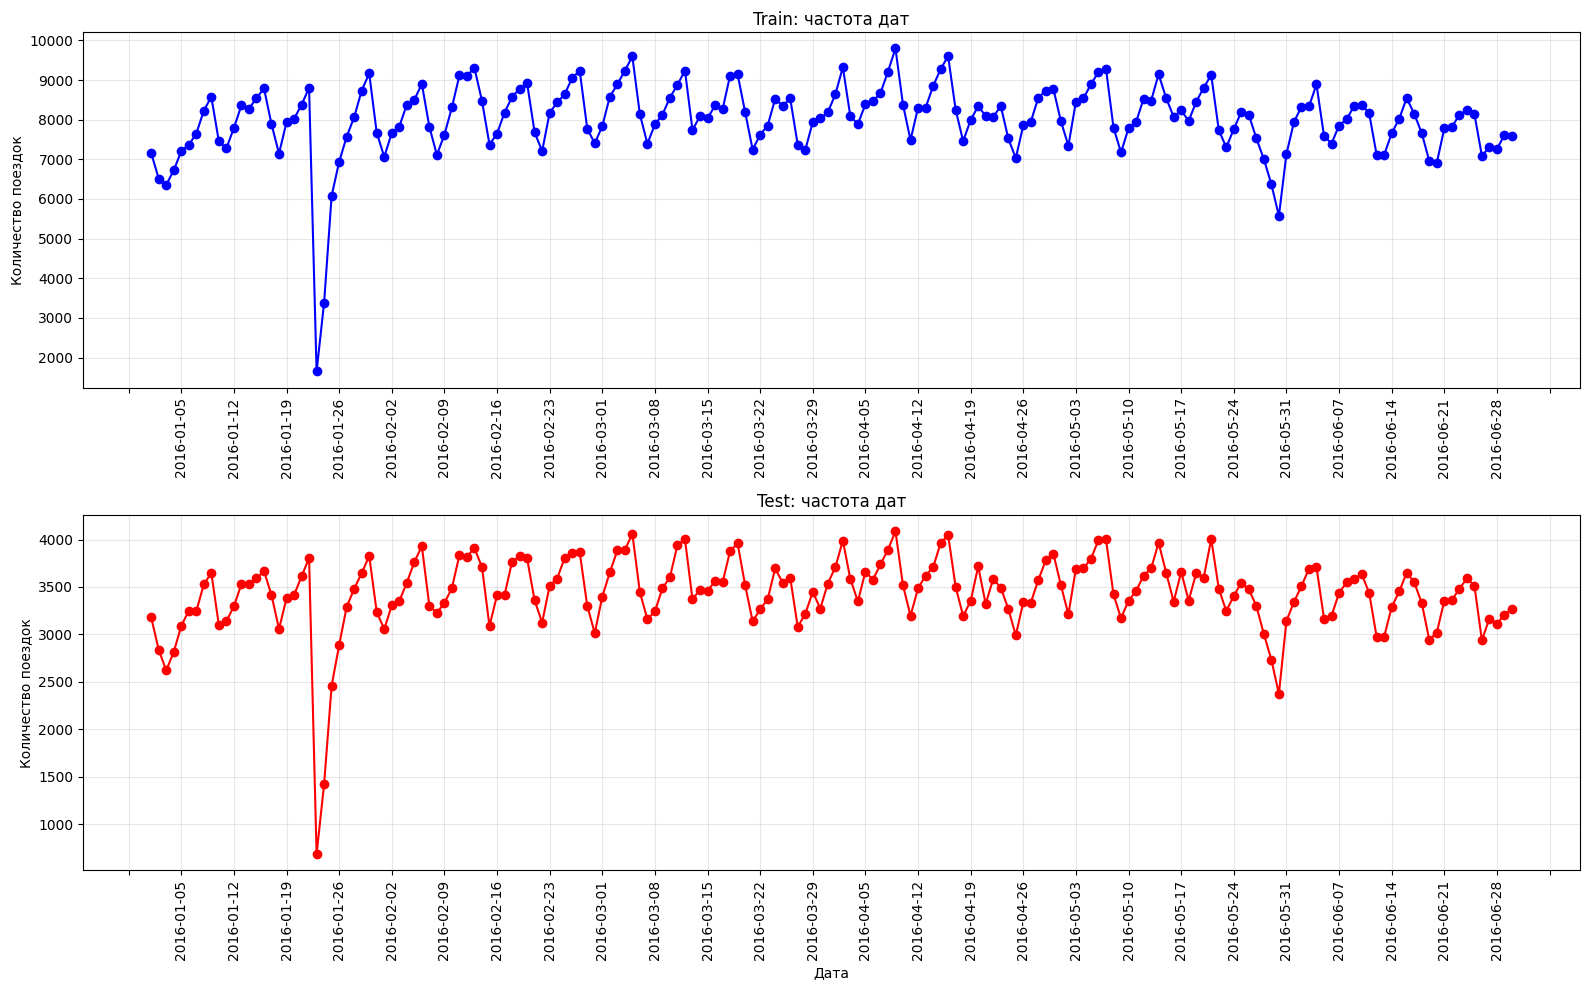

In [18]:
import matplotlib.dates as mdates

train_counts = train_df.groupby('pickup_date').size()
test_counts  = test_df.groupby('pickup_date').size()

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=False)

axes[0].plot(train_counts.index, train_counts.values, 'o-', color='blue')
axes[0].set_title('Train: частота дат')
axes[0].set_ylabel('Количество поездок')
axes[0].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
axes[0].grid(alpha=0.3)

axes[1].plot(test_counts.index, test_counts.values, 'o-', color='red')
axes[1].set_title('Test: частота дат')
axes[1].set_ylabel('Количество поездок')
axes[1].set_xlabel('Дата')
axes[1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
axes[1].grid(alpha=0.3)

for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=90)
plt.tight_layout()

## 

# Feature engineering

## First idea - to find distance (on a line) from pickup to another. We`re moving on a sphere, so can not use just Euclidean Distance

### Haversine distance - distance between 2 points on Earth

\begin{equation*}
d = 2r \cdot \arcsin{\sqrt{\sin^2{\frac{(\phi_2-\phi_1)}{2}} + \cos{\phi_1} \cdot \cos{\phi_2} \cdot \sin^2{\frac{(\lambda_2-\lambda_1)}{2}}}}
\end{equation*}

### There phi stands for latitude and lambda stands for longitude

In [19]:
RADIUS = 6371

def haversine_distance(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    dlat = lat2 - lat1
    dlng = lng2 - lng1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlng/2)**2
    c = np.arcsin(np.sqrt(a))
    d = 2 * RADIUS * c
    return d

In [20]:
def manhattan_distance(lat1, lng1, lat2, lng2):
    a = haversine_distance(lat1, lng1, lat1, lng2)
    b = haversine_distance(lat1, lng1, lat2, lng1)
    return a + b

In [21]:
def calculate_distance(df):
    df['distance_haversine'] = haversine_distance(df['pickup_latitude'],df['pickup_longitude'],df['dropoff_latitude'],df['dropoff_longitude'])
    df['distance_manhattan'] = manhattan_distance(df['pickup_latitude'].values, df['pickup_longitude'].values, 
                                                  df['dropoff_latitude'].values, df['dropoff_longitude'].values)
    return df

train_df = calculate_distance(train_df)
test_df = calculate_distance(test_df)

## Let's look at what we`ve got

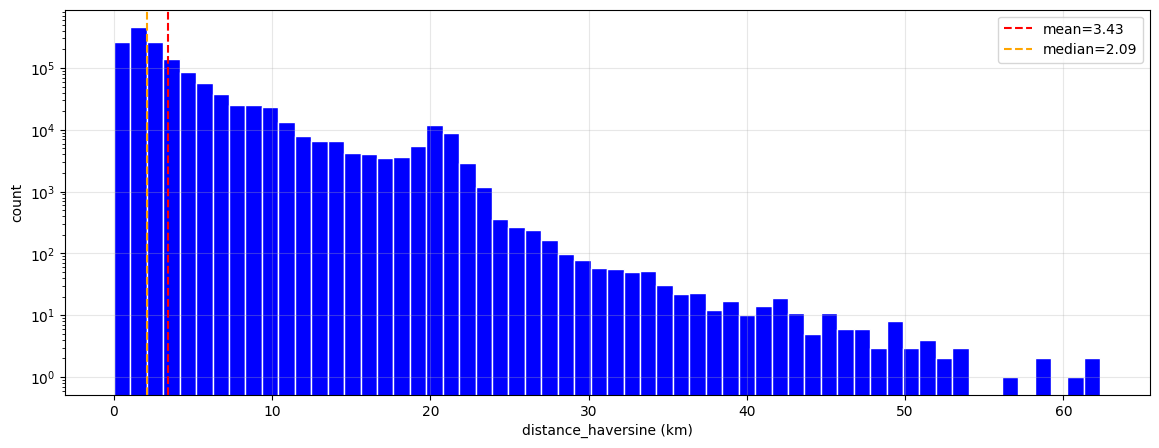

In [22]:
fig, axes = plt.subplots(1, 1, figsize=(14, 5))

data = train_df['distance_haversine'].dropna()

axes.hist(data, bins=60, color='blue', edgecolor='white')
axes.set_yscale('log')
axes.axvline(data.mean(),   color='red',    linestyle='--', label=f'mean={data.mean():.2f}')
axes.axvline(data.median(), color='orange', linestyle='--', label=f'median={data.median():.2f}')
axes.set_xlabel('distance_haversine (km)')
axes.set_ylabel('count')
axes.legend(); axes.grid(alpha=0.3)

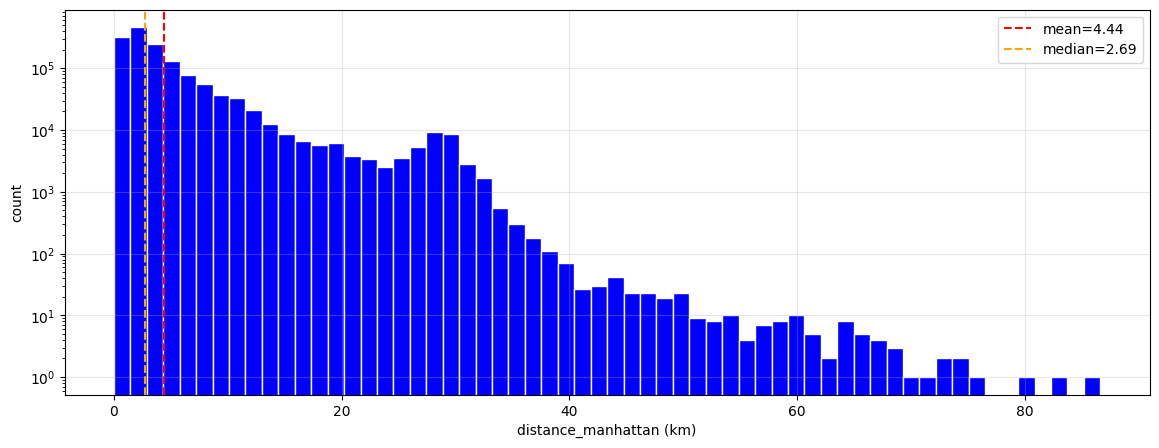

In [23]:
fig, axes = plt.subplots(1, 1, figsize=(14, 5))

data = train_df['distance_manhattan'].dropna()

axes.hist(data, bins=60, color='blue', edgecolor='white')
axes.set_yscale('log')
axes.axvline(data.mean(),   color='red',    linestyle='--', label=f'mean={data.mean():.2f}')
axes.axvline(data.median(), color='orange', linestyle='--', label=f'median={data.median():.2f}')
axes.set_xlabel('distance_manhattan (km)')
axes.set_ylabel('count')
axes.legend(); axes.grid(alpha=0.3)

## Second idea - distance to the top-10 anchors in New-York (also haversine), also with distance differrence to explain whether we're going in the direction of anchor or against it (Idea is that traffic is more massive near to anchors, so it is harder to drive in their directions)

In [24]:
def add_anchor_features(df, anchors=ANCHORS):
    for name, (alat, alon) in anchors.items():
        p = haversine_distance(df['pickup_latitude'].values,  df['pickup_longitude'].values,  alat, alon)
        d = haversine_distance(df['dropoff_latitude'].values, df['dropoff_longitude'].values, alat, alon)

        df[f'pu_dist_{name}']  = p
        df[f'do_dist_{name}']  = d
        df[f'diff_dist_{name}'] = d - p
    return df


train_df = add_anchor_features(train_df)
test_df  = add_anchor_features(test_df)

## Let`s create some date features - month, day, hour, day of week, weekday, season and part of day (good for measuring peaks on the roads)

In [25]:
def create_date_features(df):
    df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
    df["pickup_month"] = df["pickup_datetime"].dt.month
    df["pickup_day"] = df["pickup_datetime"].dt.day
    df["pickup_hour"] = df["pickup_datetime"].dt.hour
    df["pickup_day_of_week"] = df["pickup_datetime"].dt.dayofweek
    df['IsWeekend'] = df['pickup_day_of_week'].isin([5, 6]).astype(int)

    df['pickup_season'] = (df['pickup_month'] % 12 + 3) // 3

    def get_part_of_day(hour):
        if 5 <= hour < 12:
            return 'Morning'
        elif 12 <= hour < 17:
            return 'Afternoon'
        elif 17 <= hour < 21:
            return 'Evening'
        else:
            return 'Night'

    df["pickup_part_of_day"] = df["pickup_hour"].apply(get_part_of_day)

    return df

train_df = create_date_features(train_df)
test_df = create_date_features(test_df)

## Direction of movement - north/south and east/west

In [26]:
def directional_movement(df):
    df['direction_ns'] = df['dropoff_latitude'] - df['pickup_latitude']
    df['direction_ew'] = df['dropoff_longitude'] - df['pickup_longitude']

    return df

train_df = directional_movement(train_df)
test_df = directional_movement(test_df)

## Bearing, again direction of trip (For example, we can start nearly on the same hour from near places in one direction, but dropoff is different. But there must be some clue)

\begin{equation*}
\theta = \operatorname{atan2}\left(\sin(\Delta\lambda)\cos\varphi_2,\ \cos\varphi_1\sin\varphi_2 - \sin\varphi_1\cos\varphi_2\cos(\Delta\lambda)\right)
\end{equation*}

In [27]:
def add_bearing_feature(df):
    pickup_lat = np.radians(df['pickup_latitude'])
    pickup_lng = np.radians(df['pickup_longitude'])
    dropoff_lat = np.radians(df['dropoff_latitude'])
    dropoff_lng = np.radians(df['dropoff_longitude'])

    d_lng = dropoff_lng - pickup_lng

    x = np.sin(d_lng) * np.cos(dropoff_lat)
    y = np.cos(pickup_lat) * np.sin(dropoff_lat) - np.sin(pickup_lat) * np.cos(dropoff_lat) * np.cos(d_lng)
    bearing = np.degrees(np.arctan2(x, y))

    df['bearing'] = round((bearing + 360) % 360,ndigits=2 )

    return df

train_df = add_bearing_feature(train_df)
test_df = add_bearing_feature(test_df)

## Further - clusters. We have coordinants, so feels good. Have to choose k smartly, so using inertias (getting downing function)

In [28]:
coords = np.vstack([
    train_df[['pickup_latitude', 'pickup_longitude']].values,
    train_df[['dropoff_latitude', 'dropoff_longitude']].values
])

K_VALUES = [5, 10, 15, 20, 30, 40, 50, 60, 70, 75, 100, 150, 200]
inertias = []

for k in K_VALUES:
    km = MiniBatchKMeans(
        n_clusters=k,
        batch_size=10000,
        random_state=42,
        n_init=10,
    )
    km.fit(coords)
    inertias.append(km.inertia_)

    labels = km.predict(coords)

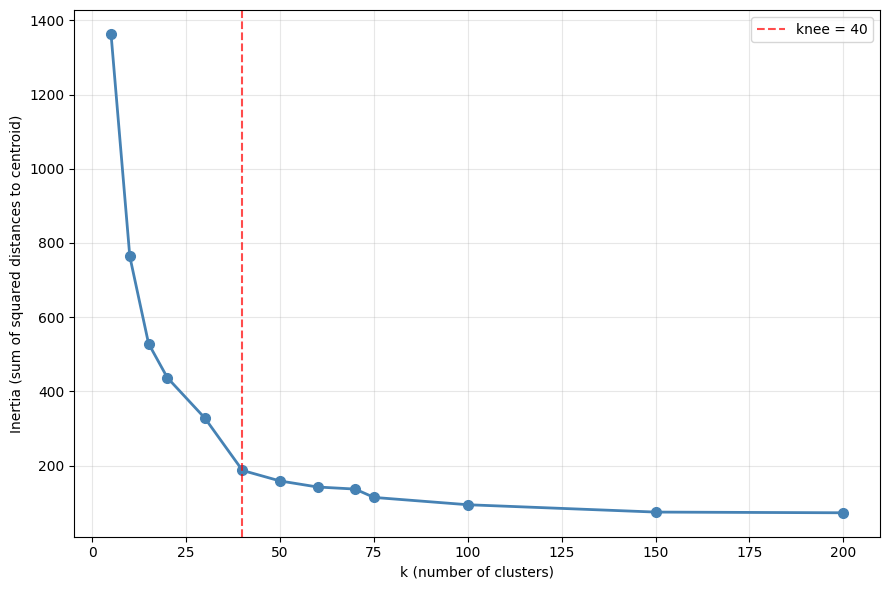

In [29]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(K_VALUES, inertias, 'o-', color='steelblue', linewidth=2, markersize=7)
ax.set_xlabel('k (number of clusters)')
ax.set_ylabel('Inertia (sum of squared distances to centroid)')
ax.grid(alpha=0.3)

kl = KneeLocator(K_VALUES, inertias, curve='convex', direction='decreasing')
if kl.knee:
    ax.axvline(kl.knee, color='red', linestyle='--', alpha=0.7,
               label=f'knee = {kl.knee}')
    ax.legend()

plt.tight_layout()
plt.show()

## Will use k=40

In [30]:
kmeans = MiniBatchKMeans(
    n_clusters=40,
    batch_size=10000,
    random_state=42,
    n_init=10
)
kmeans.fit(coords)

train_df['pickup_cluster'] = kmeans.predict(
    train_df[['pickup_latitude', 'pickup_longitude']].values
)
train_df['dropoff_cluster'] = kmeans.predict(
    train_df[['dropoff_latitude', 'dropoff_longitude']].values
)

test_df['pickup_cluster'] = kmeans.predict(
    test_df[['pickup_latitude', 'pickup_longitude']].values
)
test_df['dropoff_cluster'] = kmeans.predict(
    test_df[['dropoff_latitude', 'dropoff_longitude']].values
)

## Also want to add distance between two clusters to which our coords belong

In [31]:
centroids = kmeans.cluster_centers_

def cluster_distance(c1, c2):
    lat1, lon1 = centroids[c1]
    lat2, lon2 = centroids[c2]
    return haversine_distance(lat1, lon1, lat2, lon2)

train_df['cluster_dist'] = [
    cluster_distance(c1, c2)
    for c1, c2 in zip(train_df['pickup_cluster'], train_df['dropoff_cluster'])
]
test_df['cluster_dist'] = [
    cluster_distance(c1, c2)
    for c1, c2 in zip(test_df['pickup_cluster'], test_df['dropoff_cluster'])
]

## Well, also added some new features showing the difference in distance between pickup/dropoff coords and coords of cluster centroids (helped to gain better result in test)

In [32]:
def add_centroid_features(df):
    for i in range(len(centroids)):
        p = haversine_distance(df['pickup_latitude'].values,  df['pickup_longitude'].values,  centroids[i][0], centroids[i][1])
        d = haversine_distance(df['dropoff_latitude'].values, df['dropoff_longitude'].values, centroids[i][0], centroids[i][1])

        df[f'pu_centroid_{i+1}']  = p
        df[f'do_centroid_{i+1}']  = d
    return df


train_df = add_centroid_features(train_df)
test_df  = add_centroid_features(test_df)

## Let's plot what we did with clusters

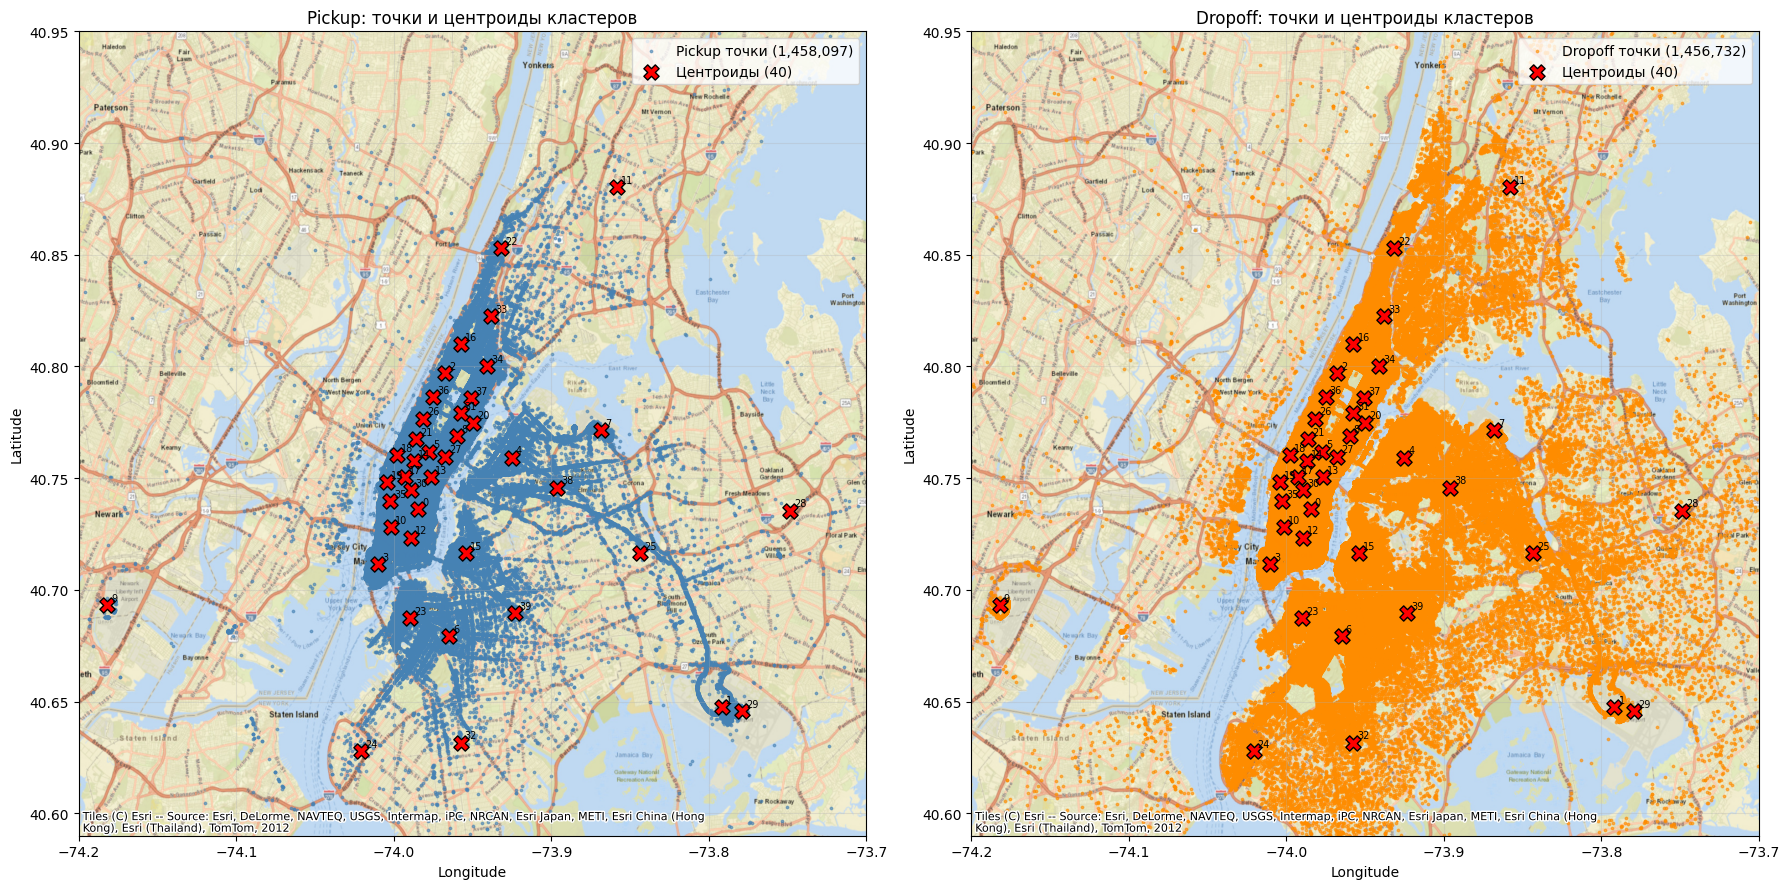

In [33]:
LAT_MIN, LAT_MAX = 40.59, 40.95
LON_MIN, LON_MAX = -74.2, -73.7

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

configs = [
    ('pickup', 'pickup_latitude', 'pickup_longitude', 'steelblue', 'Pickup'),
    ('dropoff', 'dropoff_latitude', 'dropoff_longitude', 'darkorange', 'Dropoff'),
]

for ax, (name, lat_col, lon_col, color, title) in zip(axes, configs):
    lats = train_df[lat_col].values
    lons = train_df[lon_col].values
    mask = (lats >= LAT_MIN) & (lats <= LAT_MAX) & \
           (lons >= LON_MIN) & (lons <= LON_MAX)

    idx = np.where(mask)[0]

    ax.scatter(lons[idx], lats[idx], s=3, c=color, alpha=0.6,
               label=f'{title} точки ({mask.sum():,})')

    c_lat, c_lon = centroids[:, 0], centroids[:, 1]
    cmask = (c_lat >= LAT_MIN) & (c_lat <= LAT_MAX) & \
            (c_lon >= LON_MIN) & (c_lon <= LON_MAX)

    ax.scatter(c_lon[cmask], c_lat[cmask], s=120, c='red',
               marker='X', edgecolors='black', linewidths=1.0,
               zorder=5, label=f'Центроиды ({cmask.sum()})')

    for i, (lo, la) in enumerate(zip(c_lon, c_lat)):
        if cmask[i]:
            ax.annotate(str(i), (lo, la), fontsize=7,
                        xytext=(3, 3), textcoords='offset points',
                        color='black', zorder=6)

    ax.set_xlim(LON_MIN, LON_MAX)
    ax.set_ylim(LAT_MIN, LAT_MAX)
    cx.add_basemap(ax, crs="EPSG:4326", zoom=12, source=cx.providers.Esri.WorldStreetMap)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_title(f'{title}: точки и центроиды кластеров')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')

plt.tight_layout()

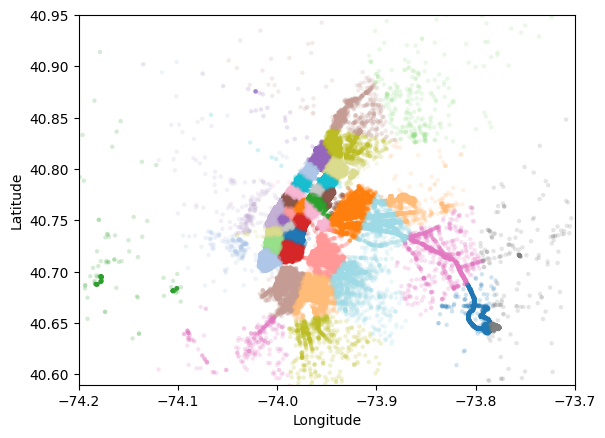

In [34]:
fig, ax = plt.subplots(ncols=1, nrows=1)
ax.scatter(train_df.pickup_longitude.values, train_df.pickup_latitude.values, s=10, lw=0,
           c=train_df.pickup_cluster.values, cmap='tab20', alpha=0.2)
ax.set_xlim([LON_MIN, LON_MAX])
ax.set_ylim([LAT_MIN, LAT_MAX])
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()

## And finally with coordinats - rotation of map (a common situation, using pca for this, trees get some new information)

In [35]:
coords = np.vstack((train_df[['pickup_latitude', 'pickup_longitude']].values,
                    train_df[['dropoff_latitude', 'dropoff_longitude']].values,
                    test_df[['pickup_latitude', 'pickup_longitude']].values,
                    test_df[['dropoff_latitude', 'dropoff_longitude']].values))

pca = PCA().fit(coords)
train_df['pickup_pca0'] = pca.transform(train_df[['pickup_latitude', 'pickup_longitude']])[:, 0]
train_df['pickup_pca1'] = pca.transform(train_df[['pickup_latitude', 'pickup_longitude']])[:, 1]
train_df['dropoff_pca0'] = pca.transform(train_df[['dropoff_latitude', 'dropoff_longitude']])[:, 0]
train_df['dropoff_pca1'] = pca.transform(train_df[['dropoff_latitude', 'dropoff_longitude']])[:, 1]
test_df['pickup_pca0'] = pca.transform(test_df[['pickup_latitude', 'pickup_longitude']])[:, 0]
test_df['pickup_pca1'] = pca.transform(test_df[['pickup_latitude', 'pickup_longitude']])[:, 1]
test_df['dropoff_pca0'] = pca.transform(test_df[['dropoff_latitude', 'dropoff_longitude']])[:, 0]
test_df['dropoff_pca1'] = pca.transform(test_df[['dropoff_latitude', 'dropoff_longitude']])[:, 1]

## Further - rush. In a rush it takes more time to drive to dropoff

In [36]:
def rush(df):
    df['is_morning_rush'] = (
        (df['pickup_hour'].between(7, 10)) &
        (df['pickup_day_of_week'] < 5)
    ).astype(int)

    df['is_evening_rush'] = (
        (df['pickup_hour'].between(16, 19)) &
        (df['pickup_day_of_week'] < 5)
    ).astype(int)

    df['is_rush_hour'] = (
        df['is_morning_rush'] | df['is_evening_rush']
    ).astype(int)

    return df

train_df = rush(train_df)
test_df = rush(test_df)

## Speed and average speed (historically grouping by hour and day of week because average speed can not be measured on test)

In [37]:
train_df['speed'] = train_df['distance_haversine'] / (train_df['trip_duration'] / 3600)

speed_by_hour = train_df.groupby(['pickup_hour', 'pickup_day_of_week'])['speed'].median().reset_index()
speed_by_hour.columns = ['pickup_hour', 'pickup_day_of_week', 'avg_speed']

train_df = train_df.merge(speed_by_hour, on=['pickup_hour', 'pickup_day_of_week'], how='left')
test_df = test_df.merge(speed_by_hour, on=['pickup_hour', 'pickup_day_of_week'], how='left')

## Distance to the nearest anchor - like mensioned earlier, it is harder to drive near them

In [38]:
anchor_names = list(ANCHORS.keys())
anchor_coords = np.array([ANCHORS[n] for n in anchor_names])

def nearest_anchor(df):
    pu_pts = df[['pickup_latitude', 'pickup_longitude']].values
    dists = haversine_distance(
        pu_pts[:, None, 0], pu_pts[:, None, 1],
        anchor_coords[None, :, 0], anchor_coords[None, :, 1],
    )
    df['pu_nearest_anchor'] = dists.argmin(axis=1).astype('int8')
    df['pu_dist_to_nearest_anchor'] = dists.min(axis=1)

    return df

train_df = nearest_anchor(train_df)
test_df = nearest_anchor(test_df)

## Now let`s use osrm. Luckily, we have a dataset containing all the data in kaggle, but it is possible to do it by hand too (but hard). For example, for one trip I can get following result:

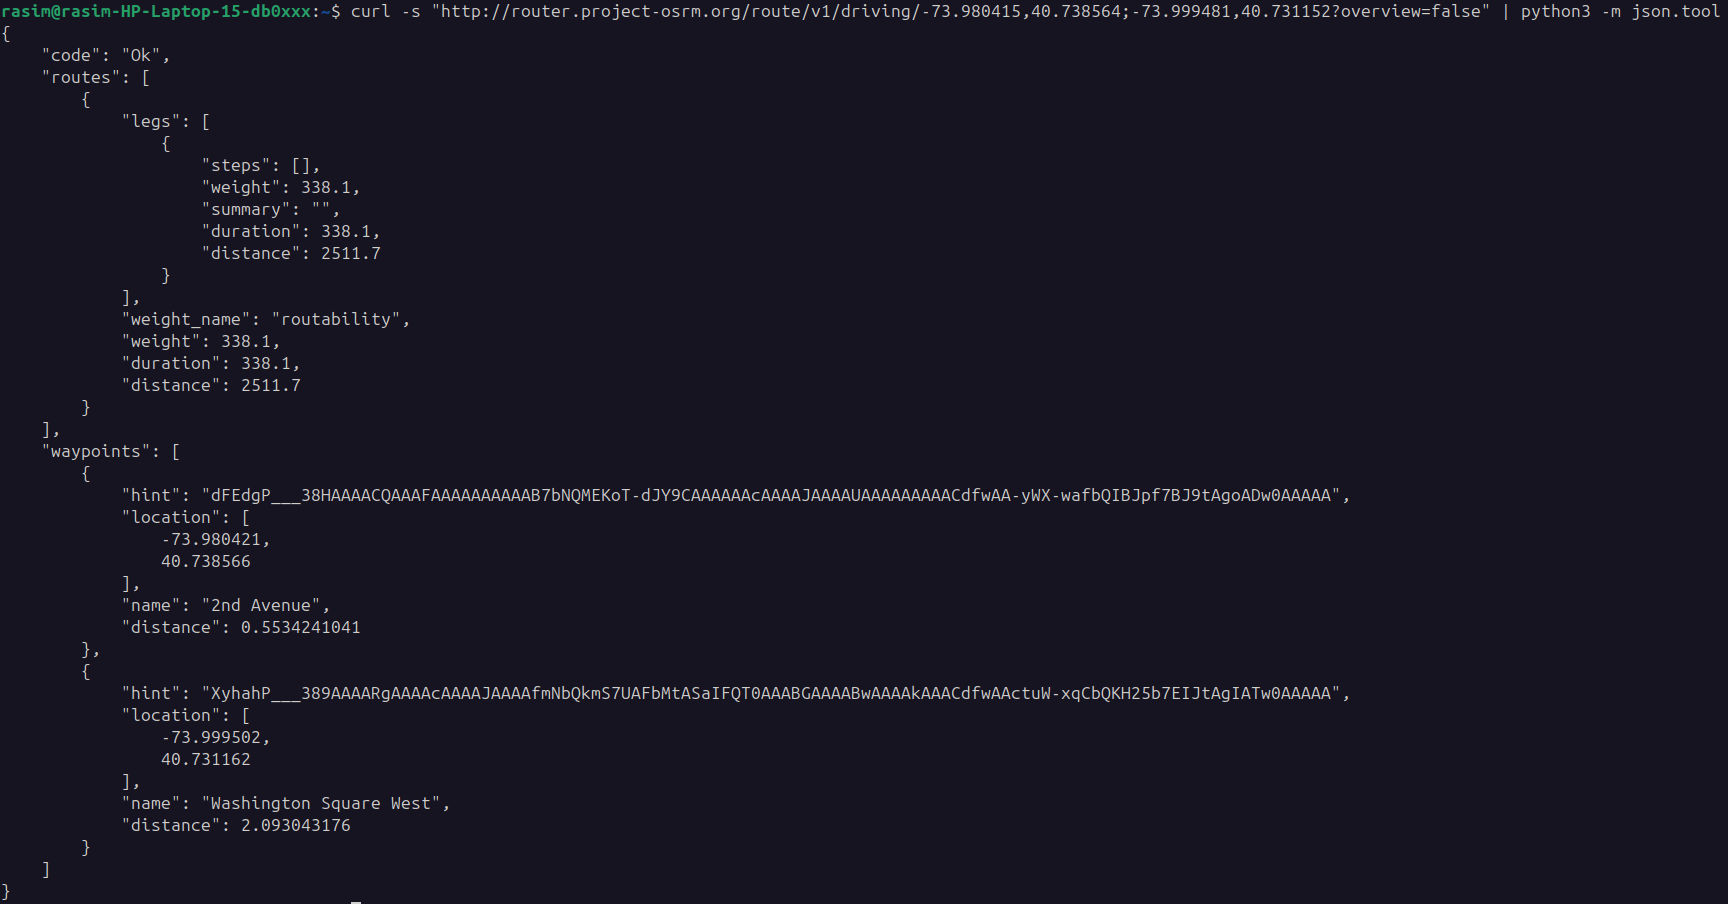

## There we have distance (not a line, but a real trip in a city) plus duration of a trip.

## Also we can use Python Library osmnx for getting a graph of New York and working with it (for every trip we can find a shortest way using Dijkstra), but its servers are dead too much. Luckily, there is open source dataset with all osrm data for this competition

In [39]:
train_osrm = train_osrm[['id', 'distance', 'duration', 'nTrafficSignals', 'nStop', 'nCrossing']].copy()
test_osrm  = test_osrm[['id', 'distance', 'duration', 'nTrafficSignals', 'nStop', 'nCrossing']].copy()

train_df['id'] = train_df['id'].astype(str)
test_df['id']  = test_df['id'].astype(str)
train_osrm['id'] = train_osrm['id'].astype(str)
test_osrm['id']  = test_osrm['id'].astype(str)

train_df = train_df.merge(train_osrm, on='id', how='left')
test_df  = test_df.merge(test_osrm,  on='id', how='left')

for col in ['distance', 'duration']:
    med = train_df[col].median()
    train_df[col] = train_df[col].fillna(med)
    test_df[col]  = test_df[col].fillna(med)

## Want to check how much is the difference between real distance and the haversine distance

In [40]:
train_df['osrm_ratio'] = train_df['distance'] / (train_df['distance_haversine'] * 1000 + 1)
test_df['osrm_ratio'] = test_df['distance'] / (test_df['distance_haversine'] * 1000 + 1)

## Also want to check the weather. We have a date and we know the city - can get info like this:

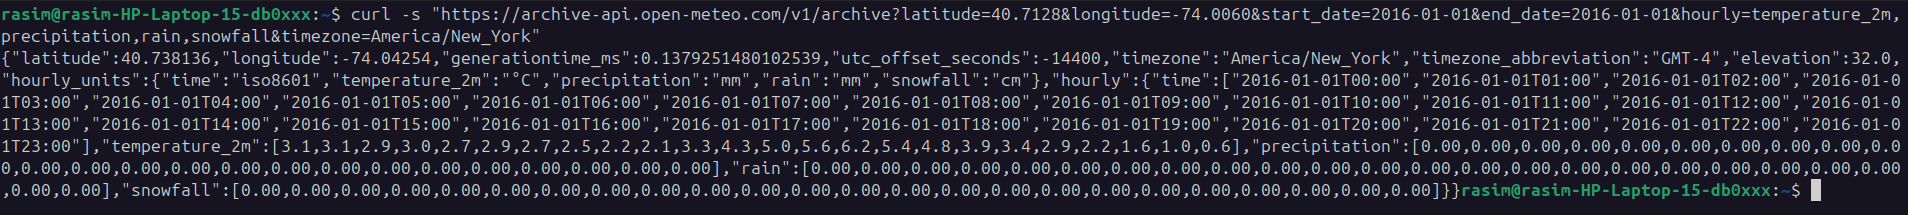

## This shows us hourly info about the weather. Can help to make predictions (it is harder to ride when it is snowy/foggy/rainy/etc.). Using asof while merge to find the nearest hour for our timestamp

In [41]:
weather['pickup_datetime'] = pd.to_datetime(weather['timestamp'])
first_row = weather.iloc[[0]].copy()
first_row['pickup_datetime'] = pd.Timestamp('2016-01-01 00:00:00')

weather = pd.concat([first_row, weather], ignore_index=True)
weather = weather.sort_values('pickup_datetime').reset_index(drop=True)

cols_to_keep = [
    'pickup_datetime', 'temp', 'windspeed', 'humidity',
    'precip', 'pressure', 'fog', 'rain', 'snow'
]
weather = weather[cols_to_keep].sort_values('pickup_datetime').copy()

train_df['pickup_datetime'] = pd.to_datetime(train_df['pickup_datetime'])
test_df['pickup_datetime']  = pd.to_datetime(test_df['pickup_datetime'])

train_df = train_df.sort_values('pickup_datetime').reset_index(drop=True)
test_df  = test_df.sort_values('pickup_datetime').reset_index(drop=True)

train_df = pd.merge_asof(
    train_df, weather,
    on='pickup_datetime',
    direction='backward',
)

test_df = pd.merge_asof(
    test_df, weather,
    on='pickup_datetime',
    direction='backward',
)

## Also I want to add some combinations of features - like distance driven in a rush, rain, etc.

In [42]:
def dist_combs(df):
    df['dist_x_rush'] = df['distance_haversine'] * df['is_rush_hour']
    
    df['dist_x_weekend'] = df['distance_haversine'] * df['IsWeekend']
    
    df['speed_x_rush'] = df['avg_speed'] * df['is_rush_hour']
    
    df['cluster_x_airport'] = df['cluster_dist'] * (
        (df['diff_dist_John F. Kennedy Airport'] < -2) | (df['diff_dist_John F. Kennedy Airport'] > 2)
    ).astype('int8')

    return df

train_df = dist_combs(train_df)
test_df = dist_combs(test_df)

In [43]:
def weather_combs(df):
    df['is_bad_weather'] = (
        (df['precip'] > 0.1) | 
        (df['snow'] == 1) | 
        (df['fog'] == 1)
    ).astype('int8')
    
    df['precip_x_rush'] = df['precip'] * df['is_rush_hour']
    df['snow_x_rush']   = df['snow']   * df['is_rush_hour']
    
    df['is_bad_weather_x_dist'] = df['is_bad_weather'] * df['distance']
    df['snow_x_dist'] = df['snow'] * df['distance']
    df['fog_x_dist'] = df['fog'] * df['distance']
    df['precip_x_dist'] = df['precip'] * df['distance']  
    
    train_df['is_bad_weather'] = (
        (train_df['precip'] > 0.1) | 
        (train_df['snow'] == 1) | 
        (train_df['fog'] == 1)
    ).astype('int8')

    return df

train_df = weather_combs(train_df)
test_df = weather_combs(test_df)

## Let's look at what we've got

In [44]:
train_df.shape

(1458363, 173)

# Preprocessing

## Logarithm of target, explained earlier

In [45]:
train_df["log_trip_duration"] = np.log1p(train_df["trip_duration"])

## Necessary columns

In [46]:
anchor_names = list(ANCHORS.keys())

PU_COLS   = [f'pu_dist_{n}'   for n in anchor_names]
DO_COLS   = [f'do_dist_{n}'   for n in anchor_names]
DIFF_COLS = [f'diff_dist_{n}' for n in anchor_names]

PU_CENTROIDS = [f'pu_centroid_{i+1}' for i in range(len(centroids))]
DO_CENTROIDS = [f'do_centroid_{i+1}' for i in range(len(centroids))]

input_cols = [
    'passenger_count', 'store_and_fwd_flag', 'vendor_id',
    'pickup_longitude', 'pickup_latitude', 
    'dropoff_longitude', 'dropoff_latitude', 
    
    'distance_haversine', 'distance_manhattan',
    
    'pickup_season', 'pickup_month', 'pickup_day', 'pickup_hour', 
    'pickup_day_of_week', 'IsWeekend', 'pickup_part_of_day',

    'direction_ns', 'direction_ew', 'bearing',

    'pickup_cluster', 'dropoff_cluster', 'cluster_dist',

    'pickup_pca0', 'pickup_pca1', 'dropoff_pca0', 'dropoff_pca1', 

    'is_rush_hour',

    'avg_speed', 

    'pu_nearest_anchor', 'pu_dist_to_nearest_anchor',

    'distance', 'duration', 
    'nTrafficSignals', 'nStop', 'nCrossing',

    'temp', 'windspeed', 'humidity',  'precip', 
    'pressure', 'fog', 'rain', 'snow', 
    
    'dist_x_rush', 'dist_x_weekend', 'speed_x_rush',  'cluster_x_airport',  
    'is_bad_weather', 'is_bad_weather_x_dist', 
     
    *PU_COLS,
    *DO_COLS,
    *DIFF_COLS,
    *PU_CENTROIDS,
    *DO_CENTROIDS
]

In [47]:
target_col = 'log_trip_duration'

In [48]:
train_inputs = train_df[input_cols].copy()
train_targets = train_df[target_col].copy()

test_inputs = test_df[input_cols].copy()

## StandardScaler for numeric cols

In [49]:
numeric_cols = list(var for var in train_inputs.columns if train_inputs[var].dtype != "O")

## OneHotEncoder for categorical columns

In [50]:
categorical_cols = list(var for var in train_inputs.columns if train_inputs[var].dtype == 'O')

In [51]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore').fit(train_inputs[categorical_cols])
encoded_cols = list(encoder.get_feature_names_out(categorical_cols))

In [52]:
train_inputs.loc[:, encoded_cols] = encoder.transform(train_inputs[categorical_cols])
test_inputs.loc[:, encoded_cols] = encoder.transform(test_inputs[categorical_cols])

In [53]:
scaler = StandardScaler()
scaler.fit(train_inputs[numeric_cols])

StandardScaler()

In [54]:
train_inputs[numeric_cols] = scaler.transform(train_inputs[numeric_cols])
test_inputs[numeric_cols] = scaler.transform(test_inputs[numeric_cols])

In [55]:
X_train = train_inputs[numeric_cols + encoded_cols]
X_test = test_inputs[numeric_cols + encoded_cols]

## Optimization via using numpy-arrays instead of pandas dataframes

In [56]:
X_train = X_train.values
X_test = X_test.values

# Prediction

## Using XGBoost as estimator

## Using Optuna for hyperparameters selection. Too much data, so using gc for some optim

In [57]:
train_x, valid_x, train_y, valid_y = train_test_split(
    X_train, train_targets, test_size=0.2, random_state=42
)

In [58]:
def objective(trial):
    try:
        xgb_params = {
            'objective': 'reg:squarederror',
            'n_jobs': -1,
            'random_state': 42,
            'subsample': 0.9,
            'colsample_bytree': 0.9,
            'device': 'cuda',
            'tree_method': 'hist',
            'eval_metric': 'rmse',
            'max_depth': trial.suggest_int('max_depth', 3, 12),
            'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 30),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 20.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 50.0, log=True),
        }

        pruning_callback = optuna.integration.XGBoostPruningCallback(
            trial, 'validation-rmse'
        )

        dtrain = xgb.DMatrix(train_x, label=train_y)
        dvalid = xgb.DMatrix(valid_x, label=valid_y)

        model = xgb.train(
            xgb_params,
            dtrain,
            num_boost_round=6000,
            evals=[(dvalid, 'validation')],
            early_stopping_rounds=50,
            callbacks=[pruning_callback],
            verbose_eval=False,
        )

        preds = model.predict(dvalid, iteration_range=(0, model.best_iteration + 1))
        rmse = root_mean_squared_error(dvalid.get_label(), preds)
        return rmse

    finally:
        gc.collect()

In [59]:
study = optuna.create_study(
    study_name='xgb_optim',
    direction='minimize',
    pruner=optuna.pruners.MedianPruner(n_warmup_steps=10),
)

study.optimize(objective, n_trials=150)

[I 2026-11-05 14:56:36,983] A new study created in memory with name: xgb_optim
[I 2026-11-05 15:04:16,484] Trial 0 finished with value: 0.3716384172439575 and parameters: {'max_depth': 10, 'learning_rate': 0.00236426575689088, 'min_child_weight': 18, 'reg_alpha': 0.0028953897459353, 'reg_lambda': 7.37469867268344}. Best is trial 0 with value: 0.3716384172439575.
[I 2026-11-05 15:06:04,332] Trial 1 finished with value: 0.3739427328109741 and parameters: {'max_depth': 3, 'learning_rate': 0.1182036889219388, 'min_child_weight': 22, 'reg_alpha': 2.081664581619436, 'reg_lambda': 49.43771394499646}. Best is trial 0 with value: 0.3716384172439575.
[I 2026-11-05 15:08:52,407] Trial 2 finished with value: 0.3701258897781372 and parameters: {'max_depth': 5, 'learning_rate': 0.03286772277731097, 'min_child_weight': 11, 'reg_alpha': 0.06064436851943277, 'reg_lambda': 10.274710412066975}. Best is trial 2 with value: 0.3701258897781372.
[I 2026-11-05 15:09:40,995] Trial 3 finished with value: 0.3712

In [60]:
print(study.best_params)

{'max_depth': 10, 'learning_rate': 0.05848930981354038, 'min_child_weight': 28, 'reg_alpha': 0.006824691402522672, 'reg_lambda': 13.477071364888907}


In [61]:
xgb_params = {
        'objective': 'reg:squarederror',
        'n_jobs': -1,
        'n_estimators': 6000,
        'random_state': 42,
        'subsample': 0.9,
        'colsample_bytree': 0.9,
        'device': 'cuda',
        'tree_method': 'hist',
        'eval_metric': 'rmse',
        'early_stopping_rounds': 50,
    }

xgb_params.update(study.best_params)
xgb_params

{'objective': 'reg:squarederror',
 'n_jobs': -1,
 'n_estimators': 6000,
 'random_state': 42,
 'subsample': 0.9,
 'colsample_bytree': 0.9,
 'device': 'cuda',
 'tree_method': 'hist',
 'eval_metric': 'rmse',
 'early_stopping_rounds': 50,
 'max_depth': 10,
 'learning_rate': 0.05848930981354038,
 'min_child_weight': 28,
 'reg_alpha': 0.006824691402522672,
 'reg_lambda': 13.477071364888907}

## Using KFold and validation on Out-Of-Fold predictions

In [62]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_xgb = np.zeros(len(X_train))
pred_xgb = np.zeros(len(X_test))

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train)):
    print(f"Fold {fold+1}/{kf.n_splits}")
    X_tr, X_val = X_train[train_idx], X_train[val_idx]
    y_tr, y_val = train_targets[train_idx], train_targets[val_idx]

    model_xgb = xgb.XGBRegressor(**xgb_params)
    model_xgb.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        verbose=False
    )
    oof_xgb[val_idx] = model_xgb.predict(X_val)
    pred_xgb += model_xgb.predict(X_test) / kf.n_splits

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5


## Results and Feature Importances

In [63]:
(mean_squared_log_error(train_df['trip_duration'], np.expm1(oof_xgb)))**0.5

0.3642303701725011

Text(0, 0.5, 'Признак')

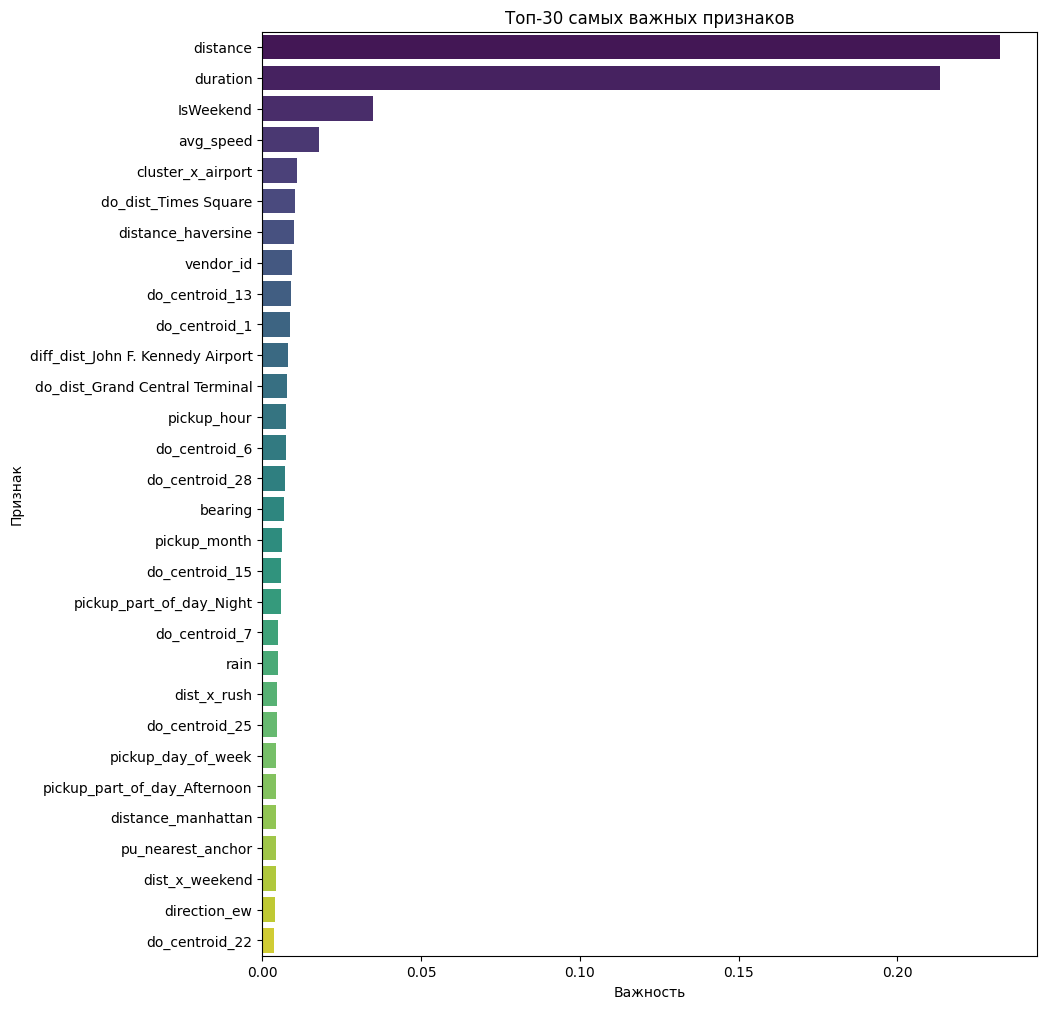

In [67]:
fi = pd.DataFrame({
    'feature':    numeric_cols + encoded_cols,
    'importance': model_xgb.feature_importances_,
}).sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(10, 12))
sns.barplot(
    x='importance', y='feature',
    data=fi.head(30), ax=ax,
    palette='viridis',
)
ax.set_title('Топ-30 самых важных признаков')
ax.set_xlabel('Важность')
ax.set_ylabel('Признак')

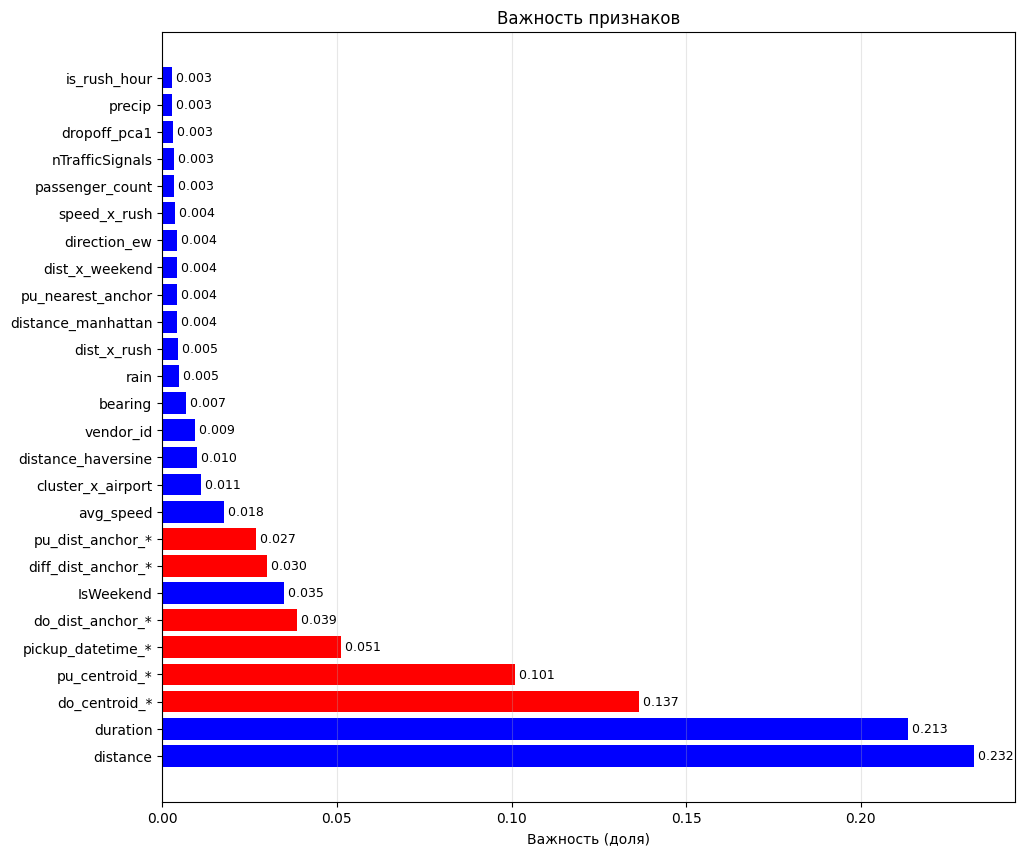

In [68]:
fi = pd.DataFrame({
    'feature':    numeric_cols + encoded_cols,
    'importance': model_xgb.feature_importances_,
})

def get_group(name):
    if name.startswith('pu_centroid'):    return 'pu_centroid_*'
    if name.startswith('do_centroid'):    return 'do_centroid_*'
    if name.startswith('pu_dist_'):       return 'pu_dist_anchor_*'
    if name.startswith('do_dist_'):       return 'do_dist_anchor_*'
    if name.startswith('diff_dist_'):     return 'diff_dist_anchor_*'
    if name.startswith('pickup_'):        return 'pickup_datetime_*'
    return name

fi['group'] = fi['feature'].apply(get_group)

top_individual = (
    fi[fi['group'] == fi['feature']]
      .sort_values('importance', ascending=False)
      .head(20)
)
top_groups = (
    fi[fi['group'] != fi['feature']]
      .groupby('group', as_index=False)['importance']
      .sum()
      .sort_values('importance', ascending=False)
)

plot_df = pd.concat([top_individual[['feature', 'importance']],
                     top_groups[['group', 'importance']].rename(columns={'group': 'feature'})])
plot_df = plot_df.sort_values('importance')

fig, ax = plt.subplots(figsize=(11, 10))
colors = ['red' if '_*' in f else 'blue' for f in plot_df['feature']]
ax.barh(plot_df['feature'], plot_df['importance'], color=colors)
ax.set_title('Важность признаков')
ax.set_xlabel('Важность (доля)')
ax.grid(axis='x', alpha=0.3)
ax.invert_yaxis()

for i, v in enumerate(plot_df['importance']):
    ax.text(v, i, f' {v:.3f}', va='center', fontsize=9)


## Don`t forget that predictions where on logarithms, so using exp(pred) for submission

In [64]:
test_preds = pred_xgb
submission = pd.DataFrame({
    'id': test_df['id'],
    'trip_duration': np.expm1(test_preds)
})

submission.to_csv('submission.csv', index=False)

In [65]:
! kaggle competitions submit -c nyc-taxi-trip-duration -f submission.csv  -m "Last Submit"

100%|██████████████████████████████████████| 16.9M/16.9M [00:01<00:00, 12.6MB/s]
Successfully submitted to New York City Taxi Trip Duration